![Python Banner](../../Image/05_02_meta_learners.png)


# 2.5. Domain Adaptation Learner (DA-Learner)

This notebook demonstrates the **Domain Adaptation Learner (DA-Learner)**, a meta-learner for estimating Conditional Average Treatment Effects (CATE) in the presence of significant domain shift between treatment and control groups. The DA-Learner uses propensity-score-based weighting to adapt the outcome models, making it robust to selection bias and distributional differences. We will use PyCausalML's `DomainAdaptationLearner` to implement this method on a real dataset, showcasing its advantages over standard meta-learners in scenarios with strong domain shift.


## Overview

The **Domain Adaptation Learner** (DA-Learner, implemented as `DomainAdaptationLearner` in EconML) is a meta-learner for estimating the Conditional Average Treatment Effect:

$$\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x]$$

from observational data. It is designed specifically for settings where the covariate distributions of the treated and control groups differ substantially — a condition variously described as **covariate shift**, **domain shift**, or **selection bias** — and where standard meta-learners consequently produce biased counterfactual predictions.

### Motivation

The T-Learner fits separate outcome models $\hat{\mu}_1(x)$ and $\hat{\mu}_0(x)$ on the treated and control subsamples, then estimates the CATE as their difference. This works well when the two groups are exchangeable in covariate distribution. In observational studies, however, treatment assignment is typically confounded: units that receive treatment are systematically different from those that do not. When covariate distributions diverge, the outcome model trained on one group must **extrapolate** to predict counterfactuals for the other group — a region of the covariate space it has not seen during training. This extrapolation degrades prediction quality and biases the resulting CATE estimates.

The DA-Learner addresses this by **reweighting each group's training distribution** to resemble the other group's distribution before fitting the outcome models, making counterfactual predictions more reliable. In this sense it is best understood as a **distribution-aligned extension of the T-Learner**, closely related in spirit to the X-Learner but with an explicit domain adaptation motivation.

---

### Algorithm

#### Step 1: Propensity Score Estimation

Estimate the propensity score $\hat{g}(x) = \hat{P}(T = 1 \mid X = x)$ using any classifier — logistic regression, random forest, gradient boosting. The propensity score quantifies how similar or different the two groups are at each point in the covariate space and serves as the basis for the importance weights in the next step.

#### Step 2: Domain-Adaptive Outcome Model Estimation

This is the defining step of the DA-Learner. Rather than fitting $\hat{\mu}_0$ and $\hat{\mu}_1$ on their respective raw subsamples, each model is trained with **importance weights** that tilt its training distribution toward the opposite group:

**Control outcome model** $\hat{\mu}_0$: fit on control units ($T_i = 0$) with sample weights

$$w_i^0 = \frac{\hat{g}(X_i)}{1 - \hat{g}(X_i)}$$

Multiplying control observations by $\hat{g}/(1-\hat{g})$ — the odds of treatment — upweights control units whose covariates resemble the treated population and downweights those that are unrepresentative of it. The resulting model is calibrated to predict $Y(0)$ accurately for individuals whose covariate profiles are typical of the *treated* group, which is precisely what is needed for counterfactual imputation.

**Treatment outcome model** $\hat{\mu}_1$: fit on treated units ($T_i = 1$) with sample weights

$$w_i^1 = \frac{1 - \hat{g}(X_i)}{\hat{g}(X_i)}$$

Symmetrically, this tilts the treated training distribution toward the control population, improving counterfactual accuracy for control units.

Any ML regressor may be used for both models. The importance-weighting scheme is an instance of **covariate shift correction** from the domain adaptation literature: when the source domain (the group used for training) and the target domain (the group for which predictions are needed) have different marginal distributions over $X$, reweighting training observations by the density ratio $p_{\text{target}}(x) / p_{\text{source}}(x)$ recovers consistency of the trained model on the target distribution. The propensity-score-based weights are proportional to this density ratio under standard regularity conditions.

#### Step 3: Pseudo-Effect Imputation

Using the domain-adapted outcome models, impute a **treatment effect residual** for each observed unit:

$$\hat{D}_i^1 = Y_i - \hat{\mu}_0(X_i) \quad \text{for treated units } (T_i = 1)$$

$$\hat{D}_i^0 = \hat{\mu}_1(X_i) - Y_i \quad \text{for control units } (T_i = 0)$$

Each residual approximates the individual treatment effect for that unit: $\hat{D}_i^1$ is the excess outcome of a treated unit above what the adapted control model predicts they would have experienced under control; $\hat{D}_i^0$ is the gain a control unit would have obtained had they been treated, according to the adapted treatment model. These pseudo-effects play the same structural role as the imputed treatment effects in the X-Learner, but benefit from the distribution alignment performed in Step 2.

#### Step 4: Final CATE Model

Pool the pseudo-effects and their associated covariates across both groups and fit a single regression model $\hat{\tau}$:

$$\hat{\tau} = M_3\!\left(\{\hat{D}_i^0, X_i\}_{T_i=0} \cup \{\hat{D}_i^1, X_i\}_{T_i=1}\right)$$

This final model directly estimates $\tau(x)$ as a smooth function of $x$, combining information from both groups. Any flexible regressor may be used for $M_3$.

---

### Full Formulation

The complete procedure in compact notation:

$$\hat{\mu}_0 = M_1\!\left(Y \sim X,\ \text{weights} = \frac{\hat{g}(X)}{1 - \hat{g}(X)},\ T=0\right)$$

$$\hat{\mu}_1 = M_2\!\left(Y \sim X,\ \text{weights} = \frac{1 - \hat{g}(X)}{\hat{g}(X)},\ T=1\right)$$

$$\hat{D}^1 = Y^1 - \hat{\mu}_0(X^1), \qquad \hat{D}^0 = \hat{\mu}_1(X^0) - Y^0$$

$$\hat{\tau} = M_3\!\left(\hat{D} \sim X,\ \text{data} = \{(X^0, \hat{D}^0)\} \cup \{(X^1, \hat{D}^1)\}\right)$$

where $M_1, M_2, M_3$ are arbitrary ML regressors and $\hat{g}(x)$ is the estimated propensity score.

---

### Relationship to Other Meta-Learners

The DA-Learner occupies a natural position in the meta-learner family. Like the **T-Learner**, it fits separate outcome models per arm. Like the **X-Learner**, it constructs pseudo-effects by cross-imputing counterfactuals and regresses them onto covariates in a final stage. Its distinguishing feature is the explicit use of importance weighting to align training distributions before outcome model fitting — a step that neither the T-Learner nor the standard X-Learner performs.

Relative to the **R-Learner** and **DR-Learner**, the DA-Learner does not directly target an orthogonalized or doubly robust objective. It does not enjoy the Neyman-orthogonality property that makes the R-Learner robust to nuisance misspecification, nor the formal double robustness guarantee of the DR-Learner. Its practical advantage lies instead in robustness to **distributional mismatch**: when covariate shift is severe and extrapolation by un-reweighted outcome models is the primary source of bias, the domain adaptation weighting provides a more targeted correction than generic orthogonalization.

### Practical Considerations

- **Propensity score quality**: The importance weights $\hat{g}/(1-\hat{g})$ and $(1-\hat{g})/\hat{g}$ can become extreme when the propensity score is near 0 or 1. In such regions, a small number of observations receive very large weights, destabilizing the outcome model fit. Weight trimming or clipping — replacing extreme weights with a fixed upper bound — is standard practice and can substantially improve stability with minimal bias cost.

- **Overlap assumption**: The DA-Learner, like all meta-learners, requires that both treatment and control units are observed across the relevant covariate support. In regions where $\hat{g}(x) \approx 0$ or $\hat{g}(x) \approx 1$, counterfactual predictions are extrapolations regardless of weighting, and CATE estimates in those regions should be interpreted with caution.

- **Choice of base learners**: The weighting scheme changes the effective training distribution seen by $M_1$ and $M_2$, which can interact with the regularization behavior of the base learner. Tree-based methods are generally robust to this, but linear models with strong regularization may still underfit the reweighted distribution in high-curvature regions.


## Implementation in Python

PyCausalML provides an implementation of the DA-Learner through the `DomainAdaptationLearner` class. Fit `DomainAdaptationLearner(learner=...)` with `learner` set to `"lm"`, `"rf"`, `"xgb"`, or `"gbr"`. SHAP uses `explain_cate()`.

## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
try:
    import pycausalml  # noqa: F401
    import causaldata  # noqa: F401
    import matplotlib  # noqa: F401
    import xgboost  # noqa: F401
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]",
        "statsmodels", "causaldata",
    ])
print("PyCausalML ready.")

%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path

from pycausalml import (
    DRLearner,
    DomainAdaptationLearner,
    LinearDML,
    RLearner,
    SLearner,
    SparseLinearDML,
    TLearner,
    XLearner,
    explain_cate,
    synthetic_data,
)
from pycausalml.data import make_multiarm_data
from pycausalml.double_machine_learning import CausalForestDML, PartiallyLinearDML

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
N_EST = 25
print("Imported PyCausalML")


PyCausalML ready.


Imported PyCausalML


### Data

Synthetic data with **confounded treatment** (propensity depends on $X_1$ via a logistic link) and an outcome that depends on treatment and $X_1$, matching the usual Python sketch:

$T \sim \mathrm{Bernoulli}(\mathrm{expit}(X_1))$, $y = (1 + 0.5 X_1) T + X_1 + \varepsilon$.

#### Simulate confounded synthetic data


In [2]:
def ate_row(name, model, X):
    cate = np.asarray(model.predict(X), dtype=float)
    info = model.average_treatment_effect(X)
    est = float(info["estimate"])
    se = float(info["std.err"])
    if not np.isfinite(se):
        se = float(np.std(cate, ddof=1) / np.sqrt(len(cate)))
        est = float(np.mean(cate))
    return {
        "learner": name,
        "ate": est,
        "se": se,
        "ci_lower": est - 1.96 * se,
        "ci_upper": est + 1.96 * se,
    }

def abs_pct_ate(pred, truth):
    denom = abs(float(np.mean(truth)))
    if denom < 1e-8:
        return np.nan
    return 100.0 * abs(float(np.mean(pred) - np.mean(truth))) / denom

def kl_divergence(pred, truth, bins=15):
    pred = np.asarray(pred, dtype=float)
    truth = np.asarray(truth, dtype=float)
    lo = float(min(pred.min(), truth.min()))
    hi = float(max(pred.max(), truth.max()))
    if not np.isfinite(lo) or hi <= lo:
        return np.nan
    hp, _ = np.histogram(pred, bins=bins, range=(lo, hi))
    hq, _ = np.histogram(truth, bins=bins, range=(lo, hi))
    hp = hp.astype(float) + 1e-3
    hq = hq.astype(float) + 1e-3
    hp /= hp.sum()
    hq /= hq.sum()
    return float(np.sum(hp * np.log(hp / hq)))

def cumulative_gain(y, w, score):
    order = np.argsort(-np.asarray(score, dtype=float))
    y = np.asarray(y, dtype=float)[order]
    w = np.asarray(w)[order]
    n = len(y)
    frac = np.arange(1, n + 1) / n
    gain = np.empty(n)
    for i in range(n):
        ww = w[: i + 1]
        yy = y[: i + 1]
        n1 = int((ww == 1).sum())
        n0 = int((ww == 0).sum())
        gain[i] = 0.0 if n1 == 0 or n0 == 0 else (yy[ww == 1].mean() - yy[ww == 0].mean()) * (i + 1) / n
    return frac, gain

def tutorial_file(name: str) -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("Tutorials") / "05_02_Meta_Learners" / "data" / name,
            Path("data") / name,
        ):
            path = cand / rel
            if path.is_file():
                return path
    raise FileNotFoundError(name)


rng = np.random.default_rng(123)
n = 1200
X = rng.normal(size=(n, 5))
prop = 1 / (1 + np.exp(-X[:, 0]))
w = rng.binomial(1, prop)
tau = 1.0 + 0.5 * X[:, 0]
y = tau * w + X[:, 0] + rng.normal(scale=0.8, size=n)
names = [f"X{i+1}" for i in range(X.shape[1])]
print("n", n, "p", X.shape[1], "treatment rate", round(float(w.mean()), 3))
print("Population mean of tau is 1 when X1 is standard normal; sample mean", round(float(tau.mean()), 3))
dal = DomainAdaptationLearner(learner="gbr", n_estimators=N_EST, random_state=123)
dal.fit(X, w, y, feature_names=names)
cate = dal.predict(X)
print("In-sample mean CATE", round(float(cate.mean()), 3))


n 1200 p 5 treatment rate 0.522
Population mean of tau is 1 when X1 is standard normal; sample mean 1.012
In-sample mean CATE 0.976


Dimensions: `nrow(X)` observations, `ncol(X)` covariates; treatment rate `mean(w)`.

For this DGP the **conditional treatment effect** is linear in the first covariate only:

$$
\tau(x) = \mathbb{E}[Y(1) - Y(0) \mid X = x] = 1 + 0.5 x_1.
$$

We use that closed form for **validation** (holdout RMSE / correlation). The **population** average effect is $\mathbb{E}[\tau(X)] = 1$ when $X_1 \sim \mathcal{N}(0,1)$.

### Fit `DomainAdaptationLearner`

The [EconML](https://econml.azurewebsites.net/) `DomainAdaptationLearner` takes three estimator choices. **PyCausalML** uses the same stages but names the *constructor* arguments after the **base learner string** you pass in (not arbitrary sklearn objects):

| EconML argument | Role | PyCausalML argument |
|-----------------|------|-------------------|
| `models` | Weighted outcome models $\hat\mu_0$, $\hat\mu_1$ on each arm (must support sample weights) | `learner` (`"lm"`, `"rf"`, `"xgb"`, `"gbr"`) |
| `final_models` | One regressor per non-control treatment: fits pseudo–treatment effects $\hat D$ on $X$ to get $\hat\tau(x)$ | `final_learner` (same options; default copies `learner`) |
| `propensity_model` | Classifier for $P(T=\text{arm}\mid X)$ vs control on the pooled $\{\text{control},\text{arm}\}$ sample | `propensity_learner` (`"logit"`) |

After `fit()`, the fitted objects are stored as **`dal$final_models`** (list, one element per treatment level vs `control_name`) and **`dal$propensity_models`** (list, parallel: arm-vs-control propensity fit used for weights in that arm’s loop).

#### Fit DA-Learner and predict CATE


#### Summarize `final_models` and `propensity_models`


In [3]:
print("Propensity model:", type(dal.propensity_).__name__)
print("Control outcome model:", type(dal.mu0_).__name__)
print("Treated outcome model:", type(dal.mu1_).__name__)
print("Final CATE model:", type(dal.final_).__name__)


Propensity model: LogisticRegression
Control outcome model: GradientBoostingRegressor
Treated outcome model: GradientBoostingRegressor
Final CATE model: GradientBoostingRegressor


### Average treatment effect (`estimate_ate`)

#### Point and interval ATE estimates


In [4]:
info = ate_row("DA-Learner", dal, X)
info["true_ate"] = float(tau.mean())
numeric = {k: v for k, v in info.items() if k != "learner"}
print(info["learner"])
print(pd.Series(numeric).round(3).to_string())

DA-Learner
ate         0.976
se          0.013
ci_lower    0.951
ci_upper    1.001
true_ate    1.012


### Holdout validation vs known $\tau(x)$

Split the data, **fit only on the training half**, predict on the test set, and compare to $1 + 0.5 X_1$. We also fit a plain **T-Learner** (`TLearner` in the same file) for contrast when selection bias is strong.

#### Holdout metrics: DA-Learner vs T-Learner


In [5]:
rng = np.random.default_rng(456)
te = rng.choice(n, size=n // 2, replace=False)
tr = np.setdiff1d(np.arange(n), te)
da_h = DomainAdaptationLearner(learner="gbr", n_estimators=N_EST, random_state=456)
t_h = TLearner(learner="gbr", n_estimators=N_EST, random_state=456)
da_h.fit(X[tr], w[tr], y[tr], feature_names=names)
t_h.fit(X[tr], w[tr], y[tr], feature_names=names)
rows = []
for label, model in (("DA-Learner", da_h), ("T-Learner", t_h)):
    pred = model.predict(X[te])
    rows.append({
        "learner": label,
        "rmse": float(np.sqrt(np.mean((pred - tau[te]) ** 2))),
        "mae": float(np.mean(np.abs(pred - tau[te]))),
        "corr": float(np.corrcoef(pred, tau[te])[0, 1]),
    })
hold_pred = {"DA-Learner": da_h.predict(X[te]), "T-Learner": t_h.predict(X[te])}
print(pd.DataFrame(rows).round(3).to_string(index=False))


   learner  rmse   mae  corr
DA-Learner 0.147 0.103 0.975
 T-Learner 0.316 0.247 0.937


#### Scatter: predicted vs true CATE on holdout


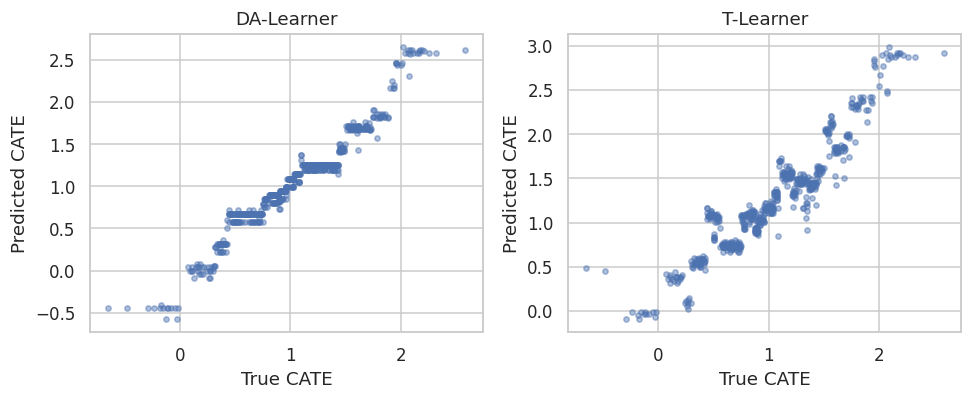

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, label in zip(axes, hold_pred):
    ax.scatter(tau[te], hold_pred[label], s=12, alpha=0.45)
    ax.set_title(label)
    ax.set_xlabel("True CATE")
    ax.set_ylabel("Predicted CATE")
fig.tight_layout()
plt.show()


### SHAP for predicted CATE (synthetic DGP, training subsample)


#### Permutation SHAP and mean $\|\mathrm{SHAP}\|$ by learner


In [7]:
models = {
    "DA-Learner": da_h,
    "T-Learner": t_h,
    "S-Learner": SLearner(learner="gbr", n_estimators=N_EST, random_state=1),
    "X-Learner": XLearner(learner="xgb", n_estimators=N_EST, random_state=1),
}
models["S-Learner"].fit(X[tr], w[tr], y[tr], feature_names=names)
models["X-Learner"].fit(X[tr], w[tr], y[tr], feature_names=names)
explanations = {}
for label, model in models.items():
    explanations[label] = explain_cate(model, X[tr], max_samples=20, n_permutations=5, random_state=1)
    print(label, np.round(explanations[label].importance(), 3))


DA-Learner [0.461 0.    0.02  0.003 0.003]
T-Learner [0.471 0.01  0.011 0.017 0.014]
S-Learner [0.314 0.    0.    0.    0.   ]
X-Learner [0.389 0.02  0.019 0.04  0.037]


### Visualize SHAP with beeswarm and waterfall plots (T-Learner with ranger base)

#### Beeswarm for each learner; waterfall for highest predicted CATE (T-Learner)


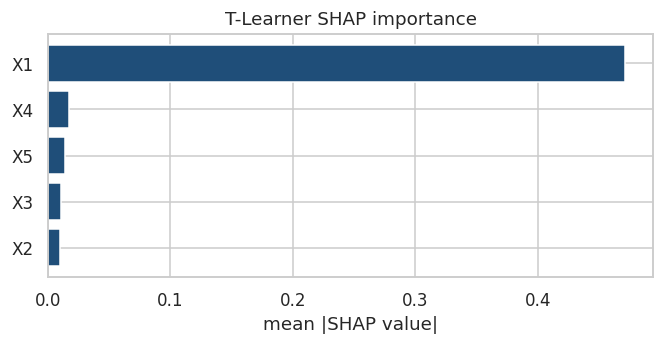

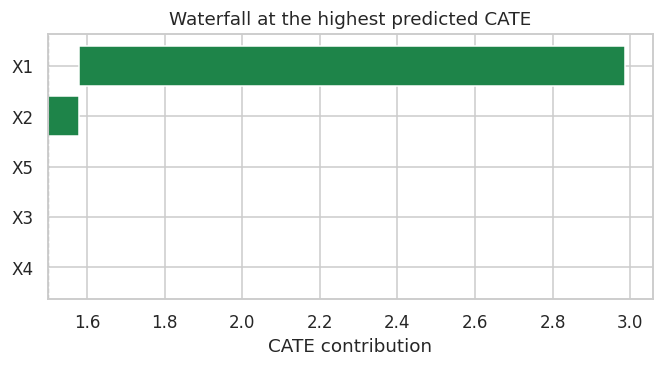

In [8]:
exp = explanations["T-Learner"]
exp.plot_importance(title="T-Learner SHAP importance")
plt.show()
exp.plot_waterfall(row=int(np.argmax(exp.predictions)), title="Waterfall at the highest predicted CATE")
plt.show()


## Summary and Conclusion

This notebook introduced the **Domain Adaptation Learner (DA-Learner)** for estimating **conditional average treatment effects (CATE)** when treatment and control groups can differ systematically in covariate distributions (**selection bias** / **domain shift**). We mapped **EconML**’s `models`, `final_models`, and `propensity_model` to **PyCausalML**’s `learner`, `final_learner`, and `propensity_learner`, and showed how **`fit()`** stores fitted **`final_models`** and **`propensity_models`** for inspection.


## References

- [EconML: `DomainAdaptationLearner`](https://econml.azurewebsites.net/) — Python reference implementation and API (models, final_models, propensity_model).
- [CausalML: meta-learners with synthetic data](https://causalml.readthedocs.io/en/latest/examples/meta_learners_with_synthetic_data.html) — related meta-learner workflows and benchmarks.
- Künzel et al. (2019). Metalearners for estimating heterogeneous treatment effects using machine learning. *PNAS*.
- Nie & Wager (2018). Quasi-oracle estimation of heterogeneous treatment effects. *Biometrika*.
